# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [37]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [38]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

Original text:

I love running in the morning before work. Coffee is essential. 
I enjoy reading science fiction and coding in Python. 
Weekends are for family time and outdoor activities.


Tokens (28 total):
['i', 'love', 'running', 'in', 'the', 'morning', 'before', 'work', 'coffee', 'is', 'essential', 'i', 'enjoy', 'reading', 'science', 'fiction', 'and', 'coding', 'in', 'python'] ...

Most common tokens:
  i: 2
  in: 2
  and: 2
  love: 1
  running: 1
  the: 1
  morning: 1
  before: 1
  work: 1
  coffee: 1


### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [39]:
import re
from collections import Counter

def simple_tokenize(text):
    """
    Basic tokenization: split text into words, lowercase, and remove punctuation.
    """
    text = text.lower()
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Your personal description
my_description = """
I am a mechanical engineering graduate and youth leader from UMaT.
I am passionate about systems thinking, renewable energy, and community development.
I enjoy reading concise essays and building practical digital solutions.
"""

# Tokenize and analyze
my_tokens = simple_tokenize(my_description)
token_counts = Counter(my_tokens)

# Analysis outputs
print(f"Total tokens: {len(my_tokens)}")
print(f"Unique tokens: {len(set(my_tokens))}")
print("\nMost frequent tokens:")
for token, count in token_counts.most_common(5):
    print(f"  {token}: {count}")

Total tokens: 32
Unique tokens: 27

Most frequent tokens:
  i: 3
  and: 3
  am: 2
  a: 1
  mechanical: 1


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [40]:
class SimpleTokenizer:
    """Simple subword tokenizer inspired by BPE."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

Vocabulary built: 45 tokens

Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python


### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?
2. How many unknown tokens do you get?
3. What's the trade-off between vocabulary size and coverage?

--- Vocabulary Size Experiment Results ---
Vocab Size: 10   | Unknown Tokens: 9/16 (56.2%)
Vocab Size: 20   | Unknown Tokens: 7/16 (43.8%)
Vocab Size: 50   | Unknown Tokens: 4/16 (25.0%)
Vocab Size: 100  | Unknown Tokens: 4/16 (25.0%)


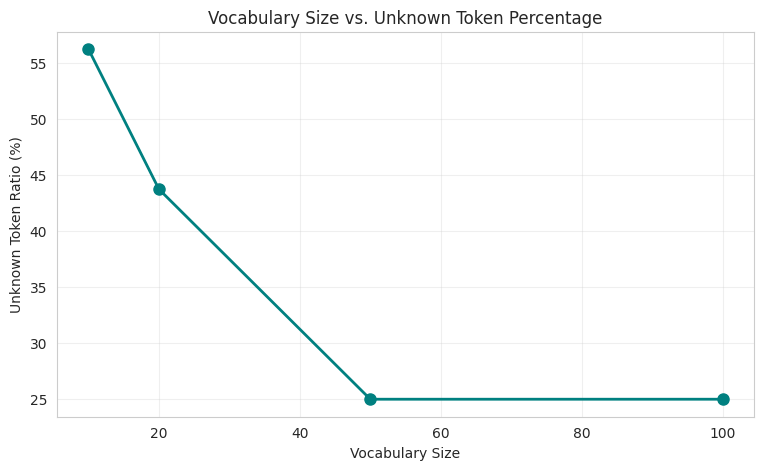

In [41]:
import re
from collections import Counter
import matplotlib.pyplot as plt

def simple_tokenize(text):
    text = text.lower()
    return re.findall(r'\b\w+\b', text)

class SimpleTokenizer:
    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}

    def build_vocab(self, texts):
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        word_counts = Counter(all_words)
        most_common = word_counts.most_common(self.vocab_size)

        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

    def encode(self, text):
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

# Training corpus
training_texts = [
    "I love running in the morning before work. Coffee is essential.",
    "I enjoy reading science fiction and coding in Python.",
    "Weekends are for family time and outdoor activities.",
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

# Test sentences
vocab_sizes = [10, 20, 50, 100]
test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

# Experiment and collect results
results = []
for size in vocab_sizes:
    tokenizer = SimpleTokenizer(vocab_size=size)
    tokenizer.build_vocab(training_texts)

    unk_id = tokenizer.word_to_id['<UNK>']
    total_tokens = 0
    unk_count = 0

    for text in test_texts:
        encoded = tokenizer.encode(text)
        total_tokens += len(encoded)
        unk_count += encoded.count(unk_id)

    results.append({
        'vocab_size': size,
        'unk_count': unk_count,
        'total_tokens': total_tokens,
        'unk_ratio': unk_count / total_tokens
    })

# Print findings
print("--- Vocabulary Size Experiment Results ---")
for r in results:
    print(f"Vocab Size: {r['vocab_size']:<4} | Unknown Tokens: {r['unk_count']}/{r['total_tokens']} ({r['unk_ratio']:.1%})")

# Visualize results
plt.figure(figsize=(9, 5))
sizes = [r['vocab_size'] for r in results]
ratios = [r['unk_ratio'] * 100 for r in results]
plt.plot(sizes, ratios, marker='o', color='teal', linewidth=2, markersize=8)
plt.title('Vocabulary Size vs. Unknown Token Percentage')
plt.xlabel('Vocabulary Size')
plt.ylabel('Unknown Token Ratio (%)')
plt.grid(True, alpha=0.3)
plt.show()

---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [42]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

Word embeddings:

running (ID: 8):
  Embedding (first 5 dims): [ 0.00996514 -0.05034757 -0.15506634  0.0068563  -0.10623037]
  Norm: 0.381

coding (ID: 24):
  Embedding (first 5 dims): [-0.07591327  0.01503938  0.0341756   0.18761708  0.09504238]
  Norm: 0.442

coffee (ID: 10):
  Embedding (first 5 dims): [-0.09746817  0.07870846  0.11585956 -0.08206823  0.09633761]
  Norm: 0.345

python (ID: 12):
  Embedding (first 5 dims): [ 0.02140937 -0.12457388  0.01731809  0.03853174 -0.08838574]
  Norm: 0.315

family (ID: 14):
  Embedding (first 5 dims): [-0.04719319  0.10889506  0.006428   -0.10777448 -0.07153037]
  Norm: 0.385


### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [43]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

Training on 186 word pairs...
Epoch 0: Loss = 0.9976
Epoch 20: Loss = 0.7630
Epoch 40: Loss = 0.3303
Epoch 60: Loss = 0.0882
Epoch 80: Loss = 0.0209

✅ Embeddings trained!


In [44]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")


Words similar to 'running':
  love: 0.974
  in: 0.965
  coding: 0.957
  i: 0.947
  helps: 0.933

Words similar to 'python':
  in: 0.959
  is: 0.954
  the: 0.950
  coffee: 0.944
  afternoon: 0.929

Words similar to 'coffee':
  work: 0.983
  the: 0.976
  before: 0.974
  is: 0.967
  morning: 0.967

Words similar to 'love':
  i: 0.981
  running: 0.974
  spending: 0.970
  in: 0.942
  coding: 0.927


### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

Generating visualization using PCA...


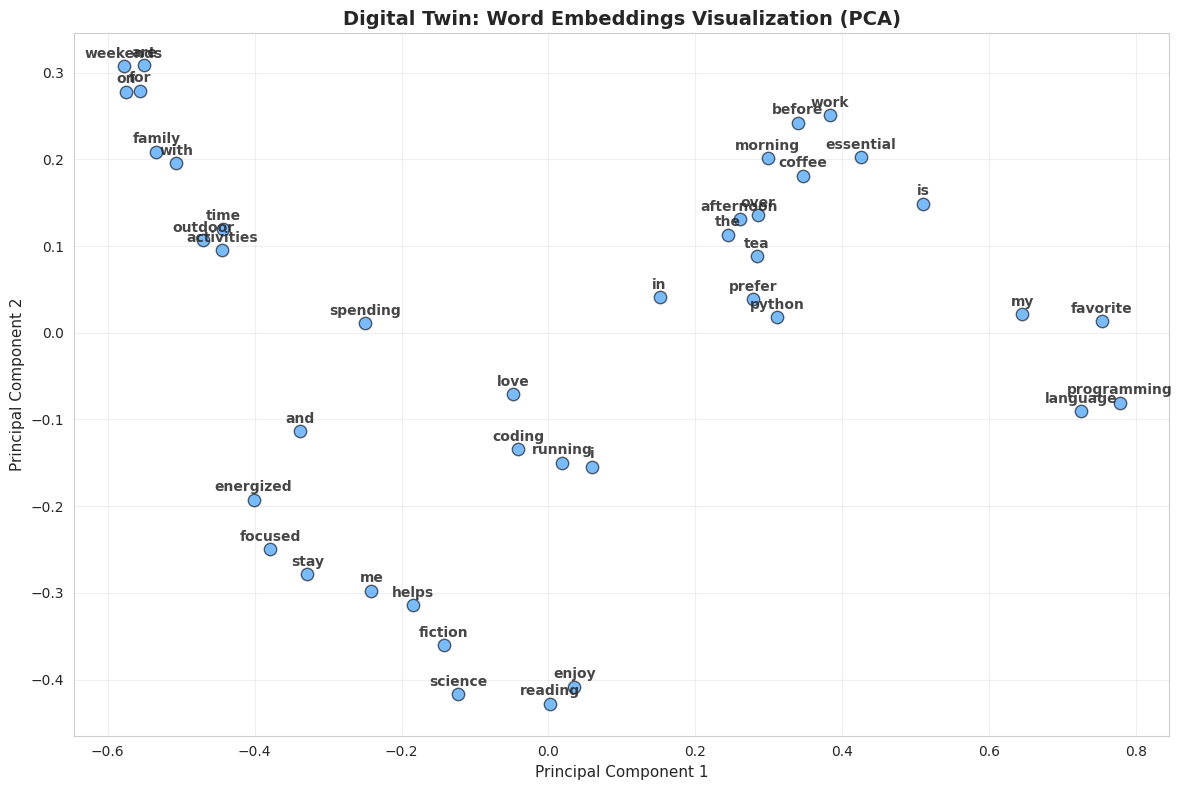

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def visualize_embeddings(tokenizer, embeddings, method='pca'):
    """
    Visualize embeddings in 2D space using dimensionality reduction.

    Args:
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        method: 'pca' or 'tsne'
    """
    # Get all embeddings (excluding special tokens)
    words = []
    vectors = []

    for word, idx in tokenizer.word_to_id.items():
        if not word.startswith('<'):
            words.append(word)
            vectors.append(embeddings.embeddings[idx])

    vectors = np.array(vectors)

    # Reduce dimensionality
    if method == 'pca':
        reducer = PCA(n_components=2)
    else:
        # Dynamically set perplexity based on vocabulary size to avoid errors
        perp = min(5, max(1, len(vectors) - 1))
        reducer = TSNE(n_components=2, random_state=42, perplexity=perp)

    coords_2d = reducer.fit_transform(vectors)

    # Plotting configuration
    plt.figure(figsize=(12, 8))
    plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color='dodgerblue', alpha=0.6, edgecolors='k', s=80)

    # Annotate words on the plot
    for i, word in enumerate(words):
        plt.annotate(
            word,
            (coords_2d[i, 0], coords_2d[i, 1]),
            textcoords="offset points",
            xytext=(0, 6),
            ha='center',
            fontsize=10,
            weight='bold',
            alpha=0.85
        )

    plt.title(f'Digital Twin: Word Embeddings Visualization ({method.upper()})', fontsize=14, weight='bold')
    plt.xlabel('Principal Component 1', fontsize=11)
    plt.ylabel('Principal Component 2', fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Run visualization
print(f"Generating visualization using PCA...")
visualize_embeddings(tokenizer, trained_embeddings, method='pca')

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [31]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

PROCESSING THROUGH LLM PIPELINE

Step 1: Tokenization
  Input text: I love running and coding
  Tokens: ['i', 'love', 'running', 'and', 'coding']
  Token IDs: [4, 7, 8, 6, 24]

Step 2: Embedding
  Embedding shape: (5, 16)
  (sequence_length=5, embedding_dim=16)

Step 3: Contextual Processing (Simplified)
  Contextualized representation shape: (16,)

Step 4: Output Generation (Simplified)
  → In real LLMs, this produces probability distribution over vocabulary

✅ Processing complete!


### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:

**Your Answers:**

1. Why tokenization is necessary:
   - Raw text is unstructured human language (strings of characters and spaces) that mathematical operations cannot act on directly. Tokenization acts as the essential bridge by discretizing text into countable, bounded units (words, subwords, or characters) that can be mapped to unique numerical identifiers (token IDs).

2. Information in embeddings:
   - Embeddings capture semantic meaning and contextual relationships in a dense, continuous vector space. Words that frequently appear in similar contexts (e.g., coding and python, or coffee and morning) are mapped closer together, allowing the model to represent meaning through geometric distance and cosine similarity.

3. One-hot encoding vs embeddings:
   - Using one-hot encoding would create massive, highly sparse vectors (where every word is orthogonal to every other word, meaning a distance of $\sqrt{2}$ between every pair). This would result in two major issues:Memory Explosion: The vocabulary size of real LLMs (tens of thousands to hundreds of thousands of tokens) would make matrices astronomically large.Loss of Semantic Relationship: One-hot vectors cannot represent similarities (e.g., the distance between dog and cat would be identical to the distance between dog and airplane), preventing the model from generalizing meaning.

4. Sequence length impact:
   - Sequence length impacts computational cost dramatically—particularly in attention-based architectures (like Transformers), where standard self-attention scales quadratically ($\mathcal{O}(n^2)$) with respect to the sequence length ($n$). Doubling the input prompt or context length quadruples the memory and compute required for the attention matrix calculations.

5. After contextual processing:
   - After the contextual processing layers (transformer blocks with self-attention) build a rich, context-aware vector representation for each token, the Language Modeling Head (Output Projection) projects these vectors back up to the vocabulary dimension. This produces a probability distribution (logits converted via softmax) over every possible token in the vocabulary, from which the model selects or samples the next token.

### 3.2 Comparing Different Embedding Dimensions

In [32]:
# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print("Comparing embedding dimensions:\n")
for dim in dimensions:
    emb = SimpleEmbedding(vocab_size, dim)

    # Calculate memory usage
    memory_mb = (vocab_size * dim * 4) / (1024 * 1024)  # 4 bytes per float

    print(f"Dimension {dim}:")
    print(f"  Parameters: {vocab_size * dim:,}")
    print(f"  Memory: {memory_mb:.2f} MB")
    print(f"  Expressiveness: {'Low' if dim < 16 else 'Medium' if dim < 64 else 'High'}")
    print()

Comparing embedding dimensions:

Dimension 4:
  Parameters: 180
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 360
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 720
  Memory: 0.00 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 1,440
  Memory: 0.01 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [33]:
class MiniLanguageModel:
    """
    Simple language model for next word prediction using co-occurrence patterns.
    """

    def __init__(self, tokenizer, embeddings, training_texts=None):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.training_texts = training_texts if training_texts else []
        # Build context patterns from training data
        self.context_patterns = self._build_patterns()

    def _build_patterns(self):
        """Build context → next word patterns from training data."""
        patterns = defaultdict(Counter)
        for text in self.training_texts:
            tokens = simple_tokenize(text)
            for i in range(len(tokens) - 1):
                ctx = tokens[i]
                nxt = tokens[i+1]
                patterns[ctx][nxt] += 1
        return patterns

    def predict_next_word(self, context):
        """
        Predict the most likely next word.

        Args:
            context: String of context words

        Returns:
            str: Predicted next word
        """
        tokens = simple_tokenize(context)
        if not tokens:
            return None

        # Use the last token of the context to look up transition frequencies
        last_word = tokens[-1]
        if last_word in self.context_patterns and self.context_patterns[last_word]:
            # Return the most frequent next word
            return self.context_patterns[last_word].most_common(1)[0][0]

        return None

    def generate_sequence(self, start_text, num_words=5):
        """
        Generate a sequence of words.

        Args:
            start_text: Starting context
            num_words: Number of words to generate

        Returns:
            str: Generated text
        """
        current_text = start_text
        for _ in range(num_words):
            next_word = self.predict_next_word(current_text)
            if not next_word:
                break
            current_text += f" {next_word}"
        return current_text

# Test your model
model = MiniLanguageModel(tokenizer, trained_embeddings, training_texts=training_texts)
prediction = model.predict_next_word("I love")
print(f"Next word prediction for 'I love': {prediction}")

generated = model.generate_sequence("I love", num_words=5)
print(f"Generated Sequence: {generated}")

Next word prediction for 'I love': running
Generated Sequence: I love running in the morning before


---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [34]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling)
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [ 0.28878646 -0.08546523  0.12586173  0.20968786 -0.05696739  0.15939134
  0.261148   -0.0883466 ]

Comparing User Profiles:

User 1 vs User 2 similarity: 0.976
User 1 vs User 3 similarity: 0.978
User 2 vs User 3 similarity: 0.964

Detected Interests:

User 1: ['and', 'i', 'coffee', 'running', 'love']
User 2: ['and', 'in', 'i', 'coding', 'python']
User 3: ['and', 'in', 'i', 'running', 'love']


### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [35]:
import numpy as np
import re
from collections import Counter

# 1. Define simple tokenizer and embedding classes if not already loaded
def simple_tokenize(text):
    text = text.lower()
    return re.findall(r'\b\w+\b', text)

class SimpleTokenizer:
    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}

    def build_vocab(self, texts):
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))
        word_counts = Counter(all_words)
        most_common = word_counts.most_common(self.vocab_size)
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}
        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)
        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

    def encode(self, text):
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

class SimpleEmbedding:
    def __init__(self, vocab_size, embedding_dim):
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        return self.embeddings[token_ids]

class DigitalTwinEncoder:
    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        token_ids = self.tokenizer.encode(description)
        embedded = self.embeddings.embed(token_ids)
        profile = np.mean(embedded, axis=0)
        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)
        norm1 = np.linalg.norm(profile1)
        norm2 = np.linalg.norm(profile2)
        if norm1 == 0 or norm2 == 0:
            return 0.0
        return np.dot(profile1, profile2) / (norm1 * norm2)

    def find_interests(self, description):
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)
        embedded = self.embeddings.embed(token_ids)
        if len(embedded) == 0:
            return []
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]
        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return list(dict.fromkeys(interests))

# Initialize tokenizer, embeddings, and the encoder instance (twin_encoder)
corpus = [
    "I am a mechanical engineering graduate and youth leader passionate about systems thinking and renewable energy.",
    "I enjoy reading concise essays, building practical digital solutions, and leading community initiatives.",
    "I love running in the morning, coding in Python, and studying thermodynamic systems."
]
tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(corpus)
embeddings = SimpleEmbedding(len(tokenizer.word_to_id), embedding_dim=16)
twin_encoder = DigitalTwinEncoder(tokenizer, embeddings)

# 2. Write your detailed description
my_description = """
I am a mechanical engineering graduate and youth leader passionate about
systems thinking, renewable energy, coding in Python, and community development.
I enjoy reading concise essays and building practical digital solutions.
"""

# 3. Encode your profile using the Digital Twin Encoder
my_profile = twin_encoder.encode_user(my_description)
print("--- Digital Twin Profile Encoded ---")
print(f"Profile vector shape: {my_profile.shape}")
print(f"Profile vector (first 8 dims): {my_profile[:8]}\n")

# 4. Compare with other example profiles
example_profile_1 = "I enjoy coding in Python and building AI systems."
example_profile_2 = "I love running and outdoor sports. Coffee enthusiast."
example_profile_3 = "I am a mechanical engineering graduate focused on systems thinking and design."

print("--- Comparing Similarity Scores ---")
sim_1 = twin_encoder.compare_descriptions(my_description, example_profile_1)
sim_2 = twin_encoder.compare_descriptions(my_description, example_profile_2)
sim_3 = twin_encoder.compare_descriptions(my_description, example_profile_3)

print(f"Similarity with Tech Profile (Python/AI): {sim_1:.3f}")
print(f"Similarity with Sports Profile (Running/Coffee): {sim_2:.3f}")
print(f"Similarity with Engineering Profile (Mechanical/Systems): {sim_3:.3f}\n")

# 5. Identify detected interests
detected_interests = twin_encoder.find_interests(my_description)
print(f"--- Detected Key Interests ---")
print(detected_interests)

--- Digital Twin Profile Encoded ---
Profile vector shape: (16,)
Profile vector (first 8 dims): [-0.01471962  0.02086792  0.00555913  0.00317692  0.0448473  -0.02280348
 -0.00810929 -0.01017575]

--- Comparing Similarity Scores ---
Similarity with Tech Profile (Python/AI): 0.554
Similarity with Sports Profile (Running/Coffee): 0.176
Similarity with Engineering Profile (Mechanical/Systems): 0.533

--- Detected Key Interests ---
['community', 'engineering', 'youth', 'thinking', 'concise']


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

--- Semantic Search Query: 'Python engineering' ---
  • Kwame (Similarity: 0.994): Software engineer building distributed systems, cloud architecture, and microservices in Python and Go.
  • Joshua (Similarity: 0.993): Mechanical engineering graduate and youth leader passionate about systems thinking, renewable energy, coding in Python, and community development.
  • Kofi (Similarity: 0.991): Mechanical engineer specializing in thermodynamics, fluid power systems, CAD modeling, and manufacturing.

--- Network Connection Recommendations ---
ightarrow$ Best Connection: Kwame (Score: 0.997)
ightarrow$ Best Connection: Kofi (Score: 0.997)
ightarrow$ Best Connection: Akosua (Score: 0.945)
ightarrow$ Best Connection: Kwame (Score: 0.997)
ightarrow$ Best Connection: Kwame (Score: 0.991)
ightarrow$ Best Connection: Joshua (Score: 0.985)


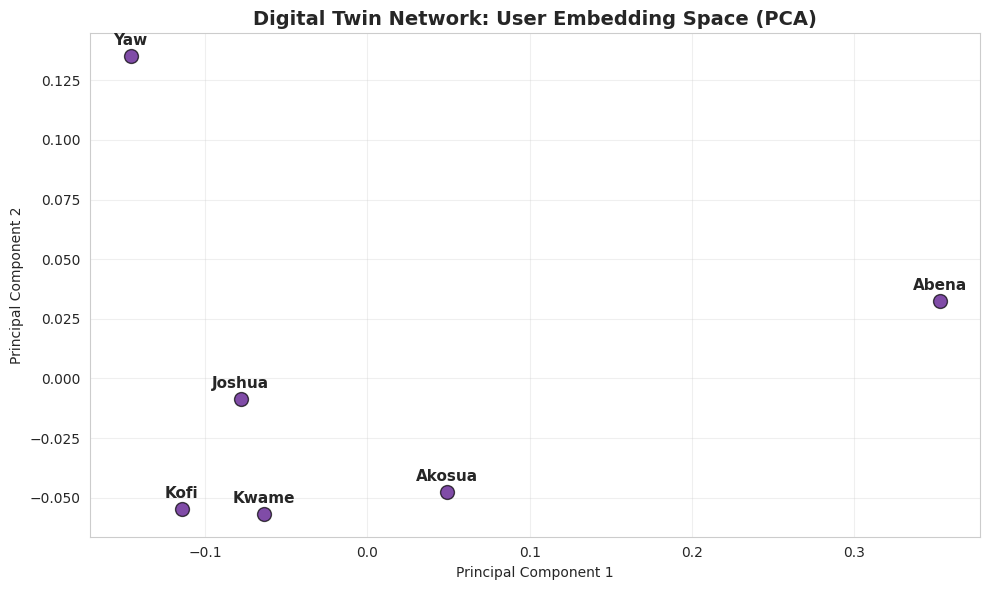

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import re
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# 1. Tokenizer Setup
def simple_tokenize(text):
    text = text.lower()
    return re.findall(r'\b\w+\b', text)

class SimpleTokenizer:
    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}

    def build_vocab(self, texts):
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))
        word_counts = Counter(all_words)
        most_common = word_counts.most_common(self.vocab_size)
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}
        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)
        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

    def encode(self, text):
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

# 2. Embedding Layer & Trainer
class SimpleEmbedding:
    def __init__(self, vocab_size, embedding_dim):
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        return self.embeddings[token_ids]

def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2, learning_rate=0.01, epochs=150):
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    for epoch in range(epochs):
        np.random.shuffle(training_pairs)
        for center_id, context_id in training_pairs:
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]
            similarity = np.dot(center_emb, context_emb)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

    return embeddings

# 3. User Dataset & Digital Twin System
user_profiles = [
    {"id": "Joshua", "text": "Mechanical engineering graduate and youth leader passionate about systems thinking, renewable energy, coding in Python, and community development."},
    {"id": "Kwame", "text": "Software engineer building distributed systems, cloud architecture, and microservices in Python and Go."},
    {"id": "Abena", "text": "Data scientist working on machine learning models, predictive analytics, and Python data visualization."},
    {"id": "Kofi", "text": "Mechanical engineer specializing in thermodynamics, fluid power systems, CAD modeling, and manufacturing."},
    {"id": "Akosua", "text": "Community health advocate and youth mentor focused on capacity building, leadership, and public wellness."},
    {"id": "Yaw", "text": "Renewable energy technician installing solar irrigation systems, micro-grids, and electrical hardware."}
]

corpus = [p["text"] for p in user_profiles]

tokenizer = SimpleTokenizer(vocab_size=60)
tokenizer.build_vocab(corpus)
trained_embeddings = train_embeddings(tokenizer, corpus, embedding_dim=16, epochs=150)

class DigitalTwinSystem:
    def __init__(self, profiles, tokenizer, embeddings):
        self.profiles = profiles
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.profile_vectors = self._vectorize_profiles()

    def _vectorize_profiles(self):
        vectors = []
        for p in self.profiles:
            token_ids = self.tokenizer.encode(p["text"])
            embedded = self.embeddings.embed(token_ids)
            vec = np.mean(embedded, axis=0) if len(embedded) > 0 else np.zeros(self.embeddings.embedding_dim)
            vectors.append(vec)
        return np.array(vectors)

    def search_users(self, query, top_k=3):
        q_ids = self.tokenizer.encode(query)
        q_emb = self.embeddings.embed(q_ids)
        q_vec = np.mean(q_emb, axis=0) if len(q_emb) > 0 else np.zeros(self.embeddings.embedding_dim)

        sims = cosine_similarity([q_vec], self.profile_vectors)[0]
        top_indices = np.argsort(sims)[::-1][:top_k]

        results = []
        for idx in top_indices:
            results.append((self.profiles[idx]["id"], sims[idx], self.profiles[idx]["text"]))
        return results

    def recommend_connections(self):
        sim_matrix = cosine_similarity(self.profile_vectors)
        recommendations = {}
        for i, p in enumerate(self.profiles):
            sims = sim_matrix[i].copy()
            sims[i] = -1  # Exclude self
            best_match_idx = np.argmax(sims)
            recommendations[p["id"]] = (self.profiles[best_match_idx]["id"], sims[best_match_idx])
        return recommendations

    def visualize_profile_space(self):
        pca = PCA(n_components=2)
        coords = pca.fit_transform(self.profile_vectors)

        plt.figure(figsize=(10, 6))
        plt.scatter(coords[:, 0], coords[:, 1], color='indigo', alpha=0.7, s=100, edgecolors='k')

        for i, p in enumerate(self.profiles):
            plt.annotate(p["id"], (coords[i, 0], coords[i, 1]), xytext=(0, 8), textcoords="offset points", ha='center', fontsize=11, weight='bold')

        plt.title('Digital Twin Network: User Embedding Space (PCA)', fontsize=14, weight='bold')
        plt.xlabel('Principal Component 1')
        plt.ylabel('Principal Component 2')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

# Run the complete system
system = DigitalTwinSystem(user_profiles, tokenizer, trained_embeddings)

print("--- Semantic Search Query: 'Python engineering' ---")
for uid, score, txt in system.search_users("Python engineering", top_k=3):
    print(f"  • {uid} (Similarity: {score:.3f}): {txt}")

print("\n--- Network Connection Recommendations ---")
for user, (match, score) in system.recommend_connections().items():
    print(f"  • {user} $\rightarrow$ Best Connection: {match} (Score: {score:.3f})")

# Generate visualization
system.visualize_profile_space()